# EquationLearner

A neural network fits data, but it does not say **what law** it learned. An
`EquationLearner` is a network you can read: its units are mathematical
functions - `sin`, products, exponentials - so that, once trained, it **is** an
equation. Pruning the small coefficients leaves the few terms that matter:
symbolic regression, inside a *nnodely* model.

This tutorial shows:

- how the learner is built: an input projection, a library of functions, an
  output combination;
- how to train it, read the equation, and prune it with a threshold;
- how to choose the library, and functions of your own;
- how to discover the law of a dynamic system from its trajectories.

In [1]:
import os

# Pick the Keras backend before nnodely (or Keras) is imported:
# "tensorflow" (the default), "torch" or "jax".
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import matplotlib.pyplot as plt
import numpy as np

from nnodely import (
    DataLoader,
    EquationLearner,
    Input,
    Linear,
    Modely,
    Output,
    Tanh,
    set_seed,
)

set_seed(0)

## How it is built

An `EquationLearner` is three stages:

1. `linear_in`, a `Linear` layer, maps the inputs to the **arguments** of the
   functions: each argument is a weighted sum of the inputs;
2. the **functions** are applied, each to its arguments - `sin` takes one,
   `multiply` two;
3. `linear_out`, a `Linear` layer, sums the function values with weights: the
   output.

`linear_in` must give exactly as many features as the functions take
arguments: `["sin", "multiply"]` take `1 + 2 = 3`. Without `linear_out` the
learner returns one feature per function.

## Discovering a law

The data comes from $y = 2\sin(x_1) + 0.5\,x_1 x_2$, which the learner does not
know. Its library holds what the law might be made of: a `sin` and a product.

In [ ]:
rng = np.random.default_rng(0)
x1_data, x2_data = rng.uniform(-2.0, 2.0, 3000), rng.uniform(-2.0, 2.0, 3000)
y_data = 2.0 * np.sin(x1_data) + 0.5 * x1_data * x2_data

x1, x2 = Input("x1", tw=1), Input("x2", tw=1)
learner = EquationLearner(
    ["sin", "multiply"],
    linear_in=Linear(features=3, bias=False),  # 1 argument for sin, 2 for multiply
    linear_out=Linear(features=1),
)
y = Output("y", learner([x1, x2]))  # the inputs are joined into one vector
law = Modely("law", inputs=[x1, x2], outputs=[y])
law.minimize("fit", y, Input("y_meas", tw=1))
law.build()

data = DataLoader(law, source={"x1": x1_data, "x2": x2_data, "y_meas": y_data})
trained = law.train(data, epochs=80, batch_size=64, lr=1e-2, printer=None)
print("loss:", trained.losses["loss"][-1])

`plot()` writes the equation the learner computes now - every coefficient,
rounded to `precision` significant digits - draws it, and returns it as a
`sympy` equation, to print or to manipulate:

Eq(y, -3.47e-9*x1**2 + 0.5*x1*x2 + 2.23e-8*x2**2 + 2*sin(x1 + 1.61e-9*x2) + 3.89e-8)


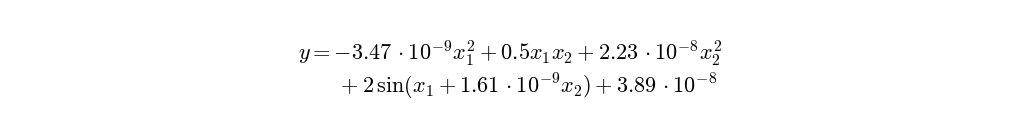

In [3]:
equation = learner.plot(precision=3)
plt.gcf().set_size_inches(10, 1.2)
print(equation)

The fit is very good, and the two true terms are there - next to traces of
others, tiny but enough to make the equation longer than the law. With noisy
data, or a larger library, those traces are much larger. That is where the
**threshold** comes in.

## Pruning with a threshold

`learner.threshold = t` drops every coefficient of the two projections smaller
than `t` in magnitude from what the model computes. The coefficients keep their
values and keep training, so a dropped one counts again if it grows past the
threshold. It can be set at any time, on a built model, without building again.

The workflow: train without a threshold, then set it and fine-tune at a lower
learning rate, so the remaining terms absorb what the dropped ones did:

In [ ]:
learner.threshold = 0.1
trained = law.train(data, epochs=80, batch_size=64, lr=2e-3, printer=None)
print("loss:", trained.losses["loss"][-1])
equation = learner.plot(precision=3)
plt.gcf().set_size_inches(10, 1.2)
print(equation)

The law, found from data alone. The threshold is saved with the model.

**Why `bias=False` on `linear_in`.** With a bias, each argument is
$w \cdot x + b$: a product $(x_1 + b_1)(x_2 + b_2)$ then also makes the terms
$b_2 x_1$, $b_1 x_2$ and a constant, which mimic other parts of the law and
leave the equation harder to read. Leaving out what the law cannot contain -
a bias, a function - narrows the search, and is the most effective help to give
a learner.

## The library of functions

`functions` is a list, each item one of:

- a **name**: `"identity"`, `"sin"`, `"cos"`, `"exp"`, `"log"`, `"sqrt"`,
  `"square"`, `"abs"`, `"tanh"`, `"sigmoid"`, `"relu"`, `"gaussian"`, ... and, of
  two arguments, `"add"`, `"subtract"`, `"multiply"`, `"divide"`, `"power"`,
  `"maximum"`, `"minimum"`, `"atan2"`;
- a **layer** class or instance, such as `Tanh`;
- a **function of streams**, its arity read from its signature, or a pair
  `(function, arity)`.

In [5]:
def ratio(a, b):
    """A function of two streams."""
    return a / (1.0 + b * b)


custom = EquationLearner(["identity", "exp", Tanh, ratio], linear_in=Linear(features=5))
print(custom([x1, x2]).shape)  # no linear_out: one feature per function

Shape(S=(), T=1, D=(4,))


A larger library can express more laws, but also more equivalent ways to fit
the same data: keep it to what the physics suggests, and compare a few seeds.

## Discovering dynamics

An `EquationLearner` is a layer like any other, so it can be one part of a
model. A pendulum swings with an acceleration that depends on its angle and its
speed; recorded trajectories give the angle, the speed, and - by a finite
difference - the acceleration. The learner finds the law of the acceleration:

In [6]:
set_seed(0)  # the same starting weights on every run
rng = np.random.default_rng(0)
dt = 0.01
runs = []
for _ in range(20):
    theta_k, omega_k = [rng.uniform(-2.5, 2.5)], [rng.uniform(-2.0, 2.0)]
    for _ in range(300):
        acceleration = (
            -9.81 * np.sin(theta_k[-1]) - 0.3 * omega_k[-1]
        )  # the unknown law
        omega_k.append(omega_k[-1] + dt * acceleration)
        theta_k.append(theta_k[-1] + dt * omega_k[-1])
    th, om = np.array(theta_k), np.array(omega_k)
    runs.append({"theta": th[:-1], "omega": om[:-1], "acc": np.diff(om) / dt})

theta, omega = Input("theta", tw=1), Input("omega", tw=1)
pendulum_law = EquationLearner(
    ["identity", "sin"],
    linear_in=Linear(features=2, bias=False),
    linear_out=Linear(features=1, bias=False),
)
alpha = Output("alpha", pendulum_law([theta, omega]))
pendulum = Modely("pendulum", inputs=[theta, omega], outputs=[alpha])
pendulum.minimize("acceleration", alpha, Input("acc", tw=1))
pendulum.build()

trajectories = DataLoader(pendulum, source=runs)
pendulum.train(trajectories, epochs=150, batch_size=64, lr=1e-2, printer=None)
print("before pruning:", pendulum_law.plot(precision=3))
plt.close()

before pruning: Eq(y, -0.302*omega - 0.00821*theta - 9.8*sin(0.000939*omega + theta))


Eq(y, -0.3*omega - 9.81*sin(theta))


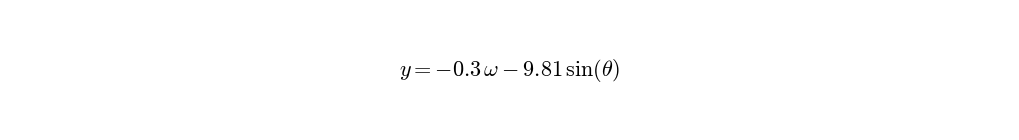

In [7]:
pendulum_law.threshold = 0.05
pendulum.train(trajectories, epochs=20, batch_size=64, lr=2e-3, printer=None)
equation = pendulum_law.plot(precision=3)
plt.gcf().set_size_inches(10, 1.2)
print(equation)

$\ddot\theta = -0.3\,\omega - 9.81\,\sin\theta$: gravity over the length,
and the damping. The variables of the equation are the names of the streams the
learner was called on - name them as you want them read.

The training is not convex: from other starting weights the learner can settle
on an equivalent-looking fit, for example a small `theta` term next to a
slightly wider `sin`. Train longer, or from a few seeds, and keep the equation
they agree on.

## Tips

- **Small libraries** first: the functions the physics suggests.
- **Leave out** biases and functions the law cannot have.
- **Train, then prune**: no threshold at first, then a threshold and a
  fine-tuning at a lower learning rate.
- **Fit what you want to read**: here the acceleration itself, not the next
  speed, in which the acceleration only weighs `dt`.
- **Several seeds**: an equation found by several is more trustworthy.

## Summary

| Task | Code |
|---|---|
| A learner | `EquationLearner(["sin", "multiply"], linear_in=Linear(3), linear_out=Linear(1))` |
| Arguments | `linear_in` features = sum of the functions' arities |
| Apply it | `learner([x1, x2])`: inputs joined into one vector |
| Read it | `learner.plot(precision=3)` -> drawn, and returned as a sympy equation |
| Prune it | `learner.threshold = 0.1`, then fine-tune at a lower `lr` |
| Own functions | a layer class, `f(a, b)`, or `(f, arity)` |

This is the last tutorial. The [User Guide](../guide/index.rst) describes every
part in full, and the [API reference](../api/index.rst) every class.